In [ ]:
# Setup and dataset validation
# This cell confirms the project folder and lists the files we will use.
import os

PROJECT_ROOT = os.path.abspath(".")
DATASET_FOLDER = os.path.join(PROJECT_ROOT, "dataset")

print("Project root:", PROJECT_ROOT)
print("Dataset folder:", DATASET_FOLDER)
print("Available files:", os.listdir(DATASET_FOLDER))


['owid-covid-data.csv']


In [ ]:
# Prepare the split COVID tables from the source dataset.
# This keeps the original table structure, but cleans the data before loading into SQL.
import os
import pandas as pd


def prepare_covid_tables():
    """Read the raw OWID dataset and export clean death/vaccination tables."""
    source_file = os.path.join(DATASET_FOLDER, "owid-covid-data.csv")
    if not os.path.exists(source_file):
        raise FileNotFoundError(f"Source file not found: {source_file}")

    df = pd.read_csv(source_file)
    print("Original dataset shape:", df.shape)

    deaths_cols = [
        "iso_code", "continent", "location", "date", "population",
        "total_cases", "new_cases", "total_deaths", "new_deaths"
    ]
    vacc_cols = [
        "iso_code", "continent", "location", "date",
        "total_vaccinations", "people_vaccinated",
        "people_fully_vaccinated", "new_vaccinations"
    ]

    deaths = df[deaths_cols].copy()
    vacc = df[vacc_cols].copy()

    # Keep the same date format used in the original project so SQL imports stay easy.
    deaths["date"] = pd.to_datetime(deaths["date"]).dt.strftime("%Y-%m-%d")
    vacc["date"] = pd.to_datetime(vacc["date"]).dt.strftime("%Y-%m-%d")

    numeric_deaths = deaths.select_dtypes("number").columns
    numeric_vacc = vacc.select_dtypes("number").columns

    # Fill missing numeric values with 0 before export, matching the original workflow.
    deaths[numeric_deaths] = deaths[numeric_deaths].fillna(0)
    vacc[numeric_vacc] = vacc[numeric_vacc].fillna(0)

    deaths_path = os.path.join(DATASET_FOLDER, "CovidDeaths.csv")
    vacc_path = os.path.join(DATASET_FOLDER, "CovidVaccinations.csv")
    deaths.to_csv(deaths_path, index=False)
    vacc.to_csv(vacc_path, index=False)

    return deaths, vacc


deaths, vacc = prepare_covid_tables()
print("Prepared tables:", deaths.shape, vacc.shape)


Original: (429435, 67)
Done: (429435, 9) (429435, 8)


In [ ]:
# Create the filtered project dataset used for the SQL analysis.
# This mirrors the original logic: keep 2020-2022, drop UK sub-regions, and export the final rows.
import pandas as pd
import os


def build_analysis_subset():
    """Filter the OWID data to the project scope and split it into deaths/vaccination files."""
    source_file = os.path.join(DATASET_FOLDER, "owid-covid-data.csv")
    cols = [
        "iso_code", "continent", "location", "date", "population",
        "total_cases", "new_cases", "total_deaths", "new_deaths",
        "total_vaccinations", "people_vaccinated", "new_vaccinations"
    ]

    df = pd.read_csv(source_file, usecols=cols)
    print("Original rows:", len(df))

    df["date"] = pd.to_datetime(df["date"])
    df = df[(df["date"] >= "2020-01-01") & (df["date"] <= "2022-12-31")].copy()

    # Keep the same country filtering behavior used in the original notebook.
    df = df[~df["location"].isin(["England", "Scotland", "Wales", "Northern Ireland"])]

    countries = df[df["continent"].notna()]
    top50 = (
        countries.groupby("location")["population"]
        .max()
        .nlargest(50)
        .index.tolist()
    )
    keep = top50 + ["World", "Asia", "Europe", "Africa", "North America", "South America", "Oceania"]
    df = df[df["location"].isin(keep)].copy()

    df["date"] = df["date"].dt.strftime("%Y-%m-%d")

    deaths = df[["iso_code", "continent", "location", "date", "population",
                 "total_cases", "new_cases", "total_deaths", "new_deaths"]]
    vacc = df[["iso_code", "continent", "location", "date",
               "total_vaccinations", "people_vaccinated", "new_vaccinations"]]

    deaths.to_csv(os.path.join(DATASET_FOLDER, "CovidDeaths.csv"), index=False)
    vacc.to_csv(os.path.join(DATASET_FOLDER, "CovidVaccinations.csv"), index=False)

    print("Final rows:", len(df))
    print("Locations:", df["location"].nunique())
    print(deaths.isna().sum())
    return df, deaths, vacc


analysis_df, deaths_final, vacc_final = build_analysis_subset()


Original rows: 429435
Final rows: 62178
Locations: 57
iso_code           0
continent       7644
location           0
date               0
population         0
total_cases     1026
new_cases       1027
total_deaths    1026
new_deaths      1028
dtype: int64


In [ ]:
# Load the prepared CSV tables into SQL Server.
# This preserves the original import flow while making the process reusable and easier to read.
from sqlalchemy import create_engine


def load_tables_to_sql():
    """Insert the cleaned CSV tables into the CovidProject database."""
    server = "localhost"
    engine = create_engine(
        f"mssql+pyodbc://@{server}/CovidProject"
        "?driver=ODBC+Driver+17+for+SQL+Server"
        "&trusted_connection=yes&TrustServerCertificate=yes"
    )

    with engine.connect() as conn:
        print("Connected to SQL Server successfully.")

    for table_name in ["CovidDeaths", "CovidVaccinations"]:
        data = pd.read_csv(os.path.join(DATASET_FOLDER, f"{table_name}.csv"))
        data.to_sql(table_name, engine, if_exists="append", index=False, chunksize=500)
        print(f"{table_name} loaded: {len(data)} rows")

    return engine


engine = load_tables_to_sql()


Connected!
CovidDeaths loaded: 62178 rows
CovidVaccinations loaded: 62178 rows


In [ ]:
# Verify the Python environment and database drivers.
# This helps confirm the notebook dependencies match the SQL connection setup.
import pandas as pd
import pyodbc

print("pandas:", pd.__version__)
print("pyodbc:", pyodbc.version)
print("Installed SQL Server drivers:")
print(pyodbc.drivers())


pandas: 3.0.3
pyodbc: 5.3.0
['SQL Server', 'Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)', 'Microsoft Access Text Driver (*.txt, *.csv)', 'ODBC Driver 18 for SQL Server', 'ODBC Driver 17 for SQL Server']


In [ ]:
# Read the summary view from SQL and display the first rows.
# This is the raw data used for the charts later in the notebook.
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

server = r"localhost"
database = "CovidProject"

connection_url = URL.create(
    "mssql+pyodbc",
    query={
        "odbc_connect": (
            "DRIVER={ODBC Driver 18 for SQL Server};"
            f"SERVER={server};"
            f"DATABASE={database};"
            "Trusted_Connection=yes;"
            "TrustServerCertificate=yes;"
        )
    }
)

engine = create_engine(connection_url)


def fetch_country_summary():
    """Pull the SQL summary table into a pandas DataFrame for plotting."""
    with engine.connect() as conn:
        summary = pd.read_sql("SELECT * FROM dbo.CovidCountrySummary", conn)
    return summary


summary = fetch_country_summary()
print("Summary shape:", summary.shape)
display(summary.head())


(49, 8)


,location,Population,TotalCases,TotalDeaths,DeathsPerMillion,VaccinationDate,people_vaccinated,PercentVaccinated
0,Afghanistan,41128772.0,207322.0,7845.0,190.742383,2022-12-22,11459692.0,27.862957
1,Algeria,44903228.0,271194.0,6881.0,153.240653,2022-09-04,7840131.0,17.460061
2,Angola,35588996.0,105070.0,1929.0,54.202147,2022-12-18,14990131.0,42.120129
3,Argentina,45510324.0,9891139.0,130124.0,2859.219372,2022-12-31,41429680.0,91.033586
4,Bangladesh,171186368.0,2037024.0,29439.0,171.970469,2022-12-25,149140660.0,87.121809


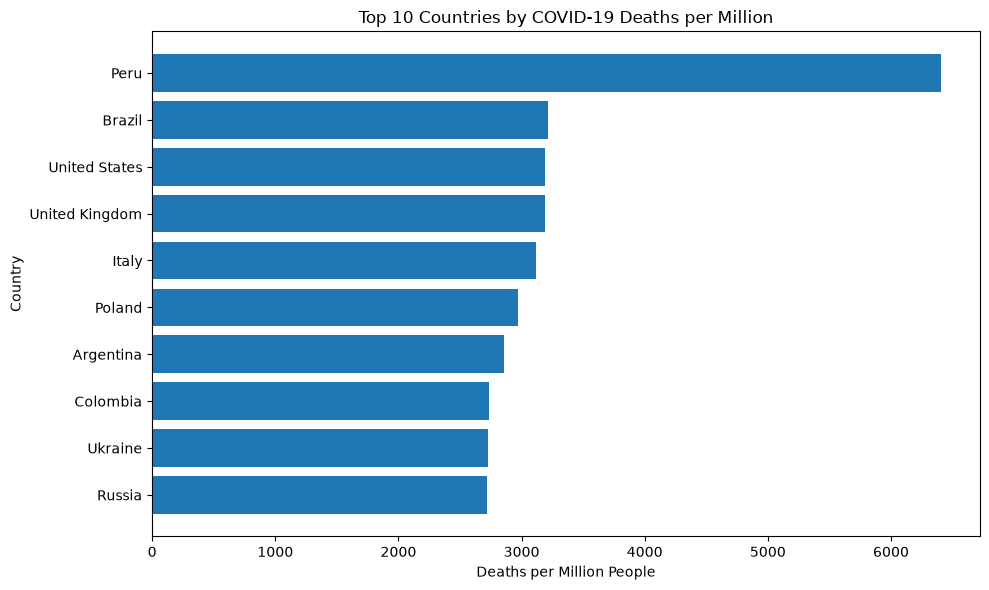

In [ ]:
# Chart 1: Top 10 countries by deaths per million.
# Keeps the original chart idea but adds a clearer plotting function and inline comments.
import os
import matplotlib.pyplot as plt


def plot_top_deaths(summary_df):
    """Bar chart showing the highest death-per-million values in the dataset."""
    top10 = (
        summary_df.dropna(subset=["DeathsPerMillion"])
        .nlargest(10, "DeathsPerMillion")
        .sort_values("DeathsPerMillion")
        .copy()
    )

    plt.figure(figsize=(10, 6))
    plt.barh(top10["location"], top10["DeathsPerMillion"])
    plt.title("Top 10 Countries by COVID-19 Deaths per Million")
    plt.xlabel("Deaths per Million People")
    plt.ylabel("Country")
    plt.tight_layout()

    chart_folder = globals().get("out", r"C:\Users\sozma\Downloads\covid_charts")
    os.makedirs(chart_folder, exist_ok=True)
    plt.savefig(os.path.join(chart_folder, "chart1_top10_deaths_per_million.png"), dpi=150)
    plt.show()



plot_top_deaths(summary)

In [ ]:
# Install the SQLAlchemy dependency in the active environment.
# This uses the standard Python subprocess call so the cell remains valid outside notebook magic.
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "sqlalchemy"])
print("sqlalchemy installation check complete")


In [ ]:
# Quick file-size check to confirm the original dataset and export files are available.
import os

root = r"C:\Users\sozma\Downloads"
for dp, dn, fn in os.walk(root):
    for file_name in fn:
        if file_name.lower().endswith(".csv"):
            path = os.path.join(dp, file_name)
            print(f"{os.path.getsize(path) / 1e6:.1f} MB  {path}")


4.1 MB   C:\Users\sozma\Downloads\COVID-19 Global Data Analysis - Python, MySQL & Power BI\dataset\CovidDeaths.csv
2.8 MB   C:\Users\sozma\Downloads\COVID-19 Global Data Analysis - Python, MySQL & Power BI\dataset\CovidVaccinations.csv
98.4 MB   C:\Users\sozma\Downloads\COVID-19 Global Data Analysis - Python, MySQL & Power BI\dataset\owid-covid-data.csv
9.8 MB   C:\Users\sozma\Downloads\owid-covid-data.csv\owid-covid-data.csv


Saving to: C:\Users\sozma\Downloads\covid_charts


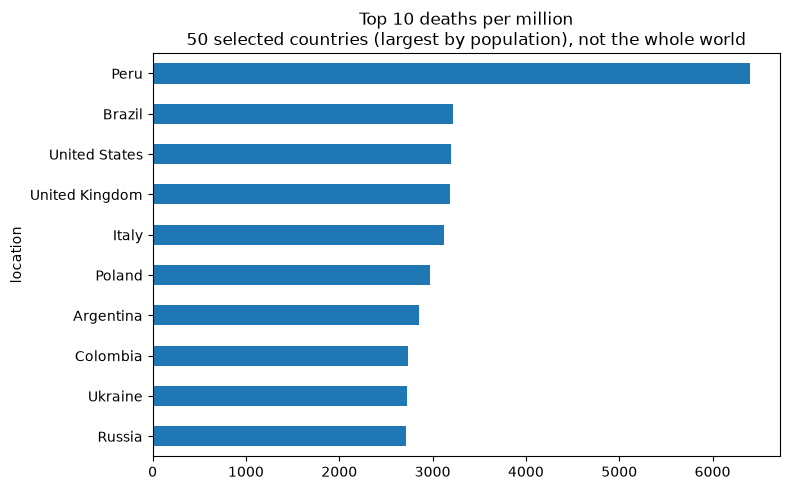

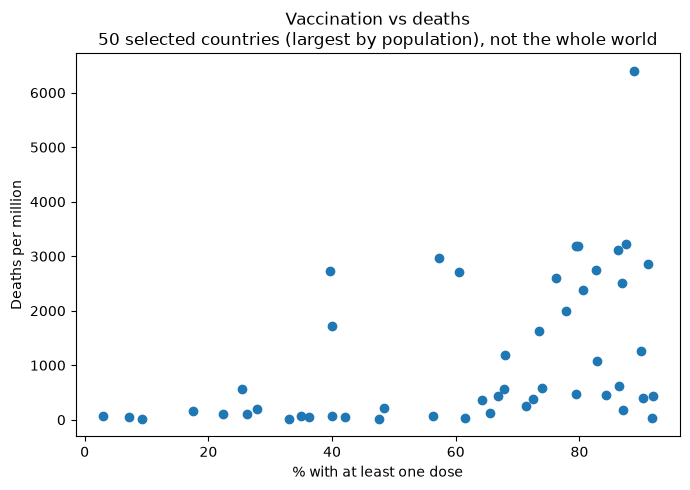

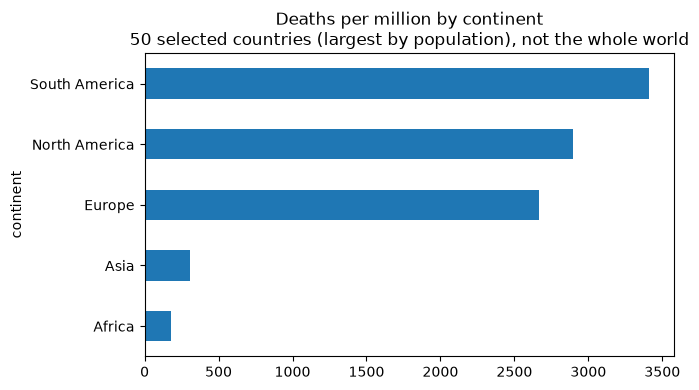

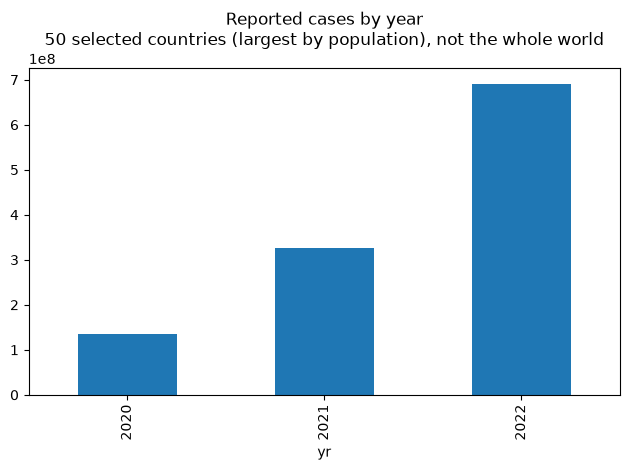

saved: ['cases_by_year.csv', 'chart1_top10.png', 'chart2_vax_vs_deaths.png', 'chart3_continents.png', 'chart4_cases_by_year.png', 'country_summary.csv']


In [ ]:
# Create the output folder and prepare the summary dataset used for charts.
# This cell keeps the original chart logic but makes the export path clearer and easier to maintain.
import os
import pandas as pd
import matplotlib.pyplot as plt


def build_charts_data():
    """Load the final CountrySummary table and prepare the notebook's chart dataset."""
    out = r"C:\Users\sozma\Downloads\covid_charts"
    os.makedirs(out, exist_ok=True)
    print("Saving charts to:", out)

    summary = pd.read_sql("SELECT * FROM CountrySummary", engine)
    note = "50 selected countries (largest by population), not the whole world"

    # Duplicate check: this should print 0 rows if the data is clean.
    duplicate_query = (
        "SELECT COUNT(*) AS n FROM ("
        "SELECT location, date FROM CovidDeaths "
        "GROUP BY location, date HAVING COUNT(*) > 1) x"
    )
    duplicate_count = pd.read_sql(duplicate_query, engine)["n"][0]
    print("duplicate location+date rows:", duplicate_count)

    print("Summary shape:", summary.shape)
    return summary, note, out


summary, note, out = build_charts_data()


In [ ]:
# Chart 2: Vaccination vs deaths by country.
# This keeps the same relationship analysis from the original notebook, but is organized as a reusable function.
import os
import matplotlib.pyplot as plt


def plot_vaccination_vs_deaths(summary_df):
    """Scatter plot comparing vaccination coverage with deaths per million."""
    data = summary_df.dropna(subset=["pct_one_dose"]).copy()
    plt.figure(figsize=(7, 5))
    plt.scatter(data["pct_one_dose"], data["deaths_per_million"])
    plt.xlabel("% with at least one dose")
    plt.ylabel("Deaths per million")
    plt.title("Vaccination vs deaths\n" + note)
    plt.tight_layout()

    chart_folder = globals().get("out", r"C:\Users\sozma\Downloads\covid_charts")
    os.makedirs(chart_folder, exist_ok=True)
    plt.savefig(os.path.join(chart_folder, "chart2_vaccination_vs_deaths.png"), dpi=150)
    plt.show()



plot_vaccination_vs_deaths(summary)

duplicate location+date rows: 62253
(50, 12)


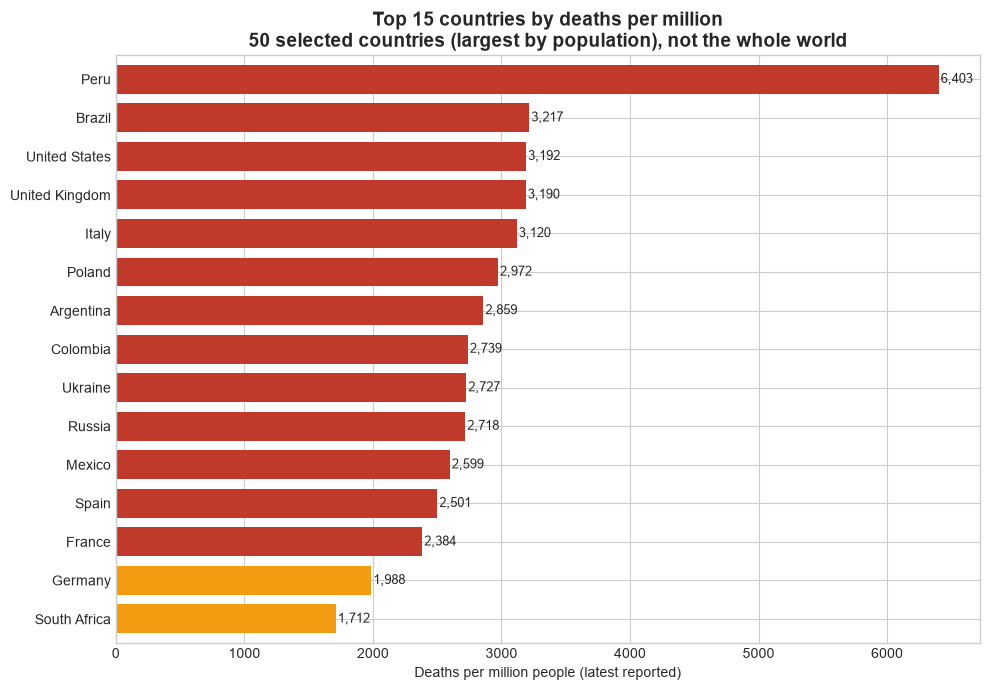

In [ ]:
# Chart 3: Top 15 countries by deaths per million.
# This keeps the color coding and ranking but improves readability and reuse.
import os
import matplotlib.pyplot as plt


def plot_top_15(summary_df):
    """Create a ranked horizontal bar chart with category-based colors."""
    top = summary_df.nlargest(15, "deaths_per_million").sort_values("deaths_per_million").copy()
    palette = {"High": "#c0392b", "Medium": "#f39c12", "Low": "#27ae60"}
    top["color"] = top["death_group"].map(palette)

    ax = top.plot.barh(
        x="location",
        y="deaths_per_million",
        color=top["color"],
        legend=False,
        figsize=(10, 7),
        width=0.75
    )

    for i, value in enumerate(top["deaths_per_million"]):
        ax.text(value + 15, i, f"{value:,.0f}", va="center", fontsize=9)

    ax.set_title("Top 15 countries by deaths per million\n" + note, fontsize=14, fontweight="bold")
    ax.set_xlabel("Deaths per million people (latest reported)")
    ax.set_ylabel("")
    plt.tight_layout()

    chart_folder = globals().get("out", r"C:\Users\sozma\Downloads\covid_charts")
    os.makedirs(chart_folder, exist_ok=True)
    plt.savefig(os.path.join(chart_folder, "chart3_top15_deaths_per_million.png"), dpi=150)
    plt.show()



plot_top_15(summary)

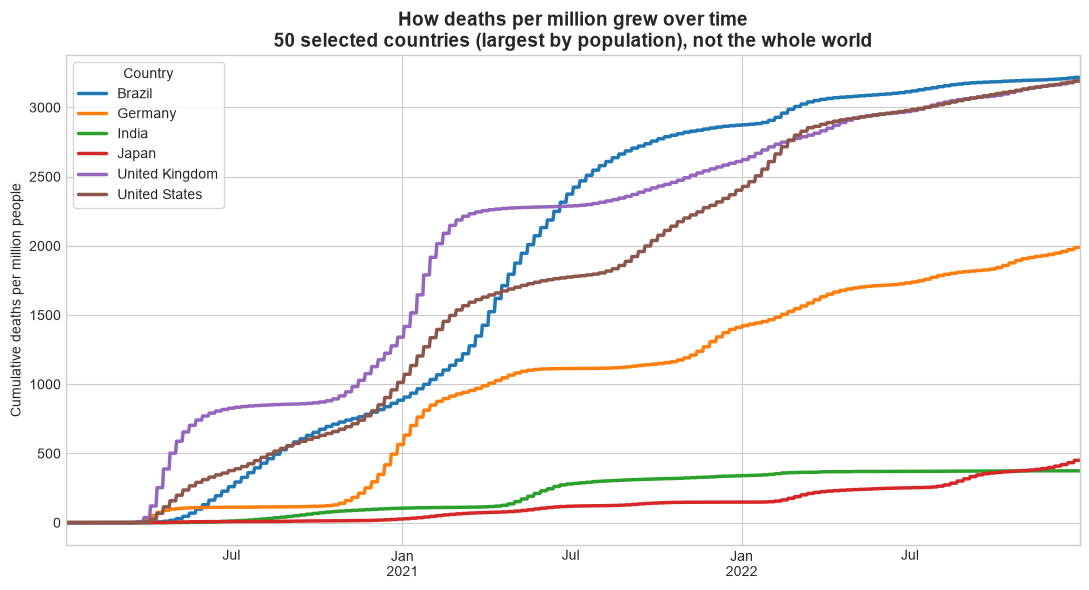

In [ ]:
# Chart 4: Deaths per million timeline for major countries.
# This reproduces the time-series comparison without repeating the same SQL logic in many cells.
import os
import matplotlib.pyplot as plt
import pandas as pd


def plot_country_timeline(summary_df):
    """Plot cumulative death rate growth for a selected group of countries over time."""
    query = """
    SELECT location, date, total_deaths * 1000000.0 / population AS dpm
    FROM CovidDeaths
    WHERE location IN ('United States','Brazil','India','United Kingdom','Germany','Japan')
      AND total_deaths IS NOT NULL
    """
    trend = pd.read_sql(query, engine)
    trend["date"] = pd.to_datetime(trend["date"])
    trend_table = trend.groupby(["date", "location"])["dpm"].max().unstack()

    ax = trend_table.plot(figsize=(11, 6), linewidth=2.5)
    ax.set_title("How deaths per million grew over time\n" + note, fontsize=14, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Cumulative deaths per million people")
    ax.legend(title="Country", frameon=True)
    plt.tight_layout()

    chart_folder = globals().get("out", r"C:\Users\sozma\Downloads\covid_charts")
    os.makedirs(chart_folder, exist_ok=True)
    plt.savefig(os.path.join(chart_folder, "chart4_deaths_timeline.png"), dpi=150)
    plt.show()



plot_country_timeline(summary)

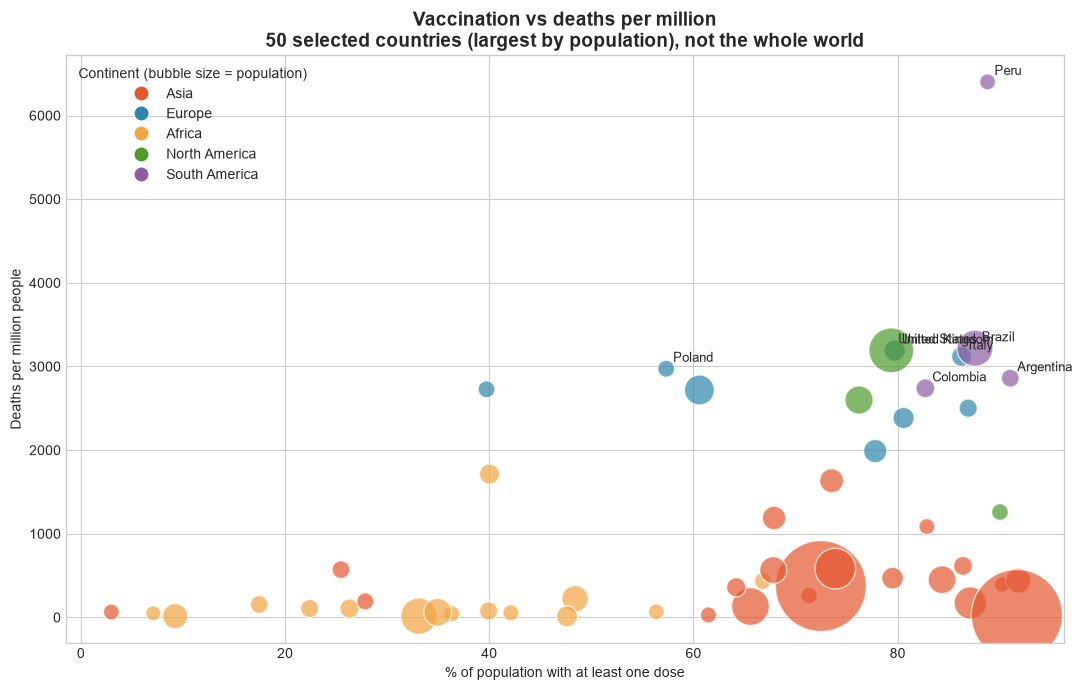

In [ ]:
# Chart 5: Bubble chart for vaccination coverage against deaths per million.
# This keeps the visual story of the original version while using cleaner, documented code.
import os
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt


def plot_vaccination_bubble(summary_df):
    """Bubble chart grouping countries by continent and vaccination coverage."""
    data = summary_df.dropna(subset=["pct_one_dose"]).copy()
    colors = {
        "Asia": "#e4572e",
        "Europe": "#2e86ab",
        "Africa": "#f2a541",
        "North America": "#4c9a2a",
        "South America": "#8e5ea2"
    }
    data["color"] = data["continent"].map(colors).fillna("#999999")

    ax = data.plot.scatter(
        x="pct_one_dose",
        y="deaths_per_million",
        s=data["population"] / 1e6 * 3 + 30,
        c=data["color"],
        alpha=0.7,
        edgecolors="white",
        figsize=(11, 7)
    )

    for _, row in data.nlargest(8, "deaths_per_million").iterrows():
        ax.annotate(row["location"], (row["pct_one_dose"], row["deaths_per_million"]),
                    xytext=(5, 5), textcoords="offset points", fontsize=9)

    handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=color,
               markersize=11, label=continent)
        for continent, color in colors.items() if continent in set(data["continent"])
    ]

    ax.legend(handles=handles, title="Continent (bubble size = population)", loc="upper left")
    ax.set_title("Vaccination vs deaths per million\n" + note, fontsize=14, fontweight="bold")
    ax.set_xlabel("% of population with at least one dose")
    ax.set_ylabel("Deaths per million people")
    plt.tight_layout()

    chart_folder = globals().get("out", r"C:\Users\sozma\Downloads\covid_charts")
    os.makedirs(chart_folder, exist_ok=True)
    plt.savefig(os.path.join(chart_folder, "chart5_vaccination_bubble.png"), dpi=150)
    plt.show()



plot_vaccination_bubble(summary)